# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapa 1: Exploración (EDA), Partición de Datos y Modelo Baseline

**Estudiantes:** Leonardo Carabajal, Brian Fernandez, Thiago Montenegro Yerumini

**Docente:** Pablo Moreira  

**Dataset asignado:** *The Festival* de H. P. Lovecraft (texto literario) - Cuentos de terror  

---

### Consignas de Etapa 1

1. **4.1.1 Carga del Corpus y EDA (Análisis Exploratorio):**
   - Estadísticas del cuento (total de caracteres, tamaño del vocabulario, longitud del texto).
   - **3 gráficos requeridos:** Distribución y desbalance de caracteres, longitud de palabras (estilo léxico) y frecuencia de puntuación.
2. **Naive Bayes desde cero**
   - Clasificamos pasajes del cuento entre sus dos grandes atmósferas: **Atmósfera Marina / Exterior** vs. **Atmósfera Subterránea / Horror Cósmico**.
   - Vemos qué palabras hacen que un párrafo sea considerado "costero" o "demoníaco/subterráneo".
3. **4.1.2 Partición de Datos**
   - Estructuración de secuencias supervisadas mediante **ventana deslizante (*sliding window*)** de longitud $L$.
   - División formal en tres particiones estrictas: **Train (70%)**, **Dev / Validación (15%)** y **Test (15%)**.
4. **4.1.3 Preprocesamiento y Modelo Baseline Oficial:**
   - Preprocesamiento y vectorización.
   - Implementación del **Modelo Baseline**: Regresión Logística Multinomial / Red de 1 capa sobre n-gramas.
   - **Cálculo y reporte de la Métrica de Número Único en Dev**
   - Matriz de confusión e inspección inicial de errores.

---


In [13]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE BIBLIOTECAS
# ==============================================================================
import os
import re
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

# Semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)

print("Entorno configurado correctamente.")


Entorno configurado correctamente.


---
# 1. Consigna 4.1.1: Carga y Análisis Exploratorio de Datos (EDA)

Cargamos el texto asignado (*The Festival* de H. P. Lovecraft) previamente depurado (removiendo encabezados de Project Gutenberg, notas editoriales y normalizando tipografía).
Inspeccionamos las dimensiones del corpus y el conjunto de caracteres únicos que formarán nuestro vocabulario de trabajo.


In [5]:
# Rutas relativas del proyecto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_PATH = BASE_DIR / "data" / "processed" / "The_Festival_clean.txt"
RAW_PATH = BASE_DIR / "db" / "The_Festival.txt"

text_file = CLEAN_PATH if CLEAN_PATH.exists() else RAW_PATH

with open(text_file, "r", encoding="utf-8") as f:
    text = f.read()

total_chars = len(text)
vocabulary = sorted(list(set(text)))
vocab_size = len(vocabulary)

print(f"Archivo cargado: {text_file.name}")
print(f"Cantidad total de caracteres: {total_chars:,}")
print(f"Tamaño del vocabulario de caracteres únicos: {vocab_size}")
print(f"Vocabulario completo:\n{repr(''.join(vocabulary))}")


Archivo cargado: The_Festival_clean.txt
Cantidad total de caracteres: 20,205
Tamaño del vocabulario de caracteres únicos: 65
Vocabulario completo:
'\n "\',-.0125689:;ABCDEFGHIJKLMNOPRSTUWYabcdefghijklmnopqrstuvwxyz—'


### Visualizaciones Relevantes del EDA (3 Gráficos Obligatorios)

#### Gráfico 1: Distribución de Frecuencia de Caracteres (Evidencia de Desbalance)
Mostramos los 20 caracteres más frecuentes y los 20 menos frecuentes. Esto demuestra de forma directa por qué predecir caracteres tiene un **fuerte desbalance de clases**: el espacio en blanco y las vocales dominan ampliamente la distribución, mientras que las letras mayúsculas y signos raros constituyen una cola larga.


C:\Users\Leonardo\AppData\Local\Temp\ipykernel_11468\579419490.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(labels_legibles[:20]), y=list(char_counts.values[:20]), ax=axes[0], palette="Blues_r", legend=False)
C:\Users\Leonardo\AppData\Local\Temp\ipykernel_11468\579419490.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(labels_legibles[-20:]), y=list(char_counts.values[-20:]), ax=axes[1], palette="Reds_r", legend=False)


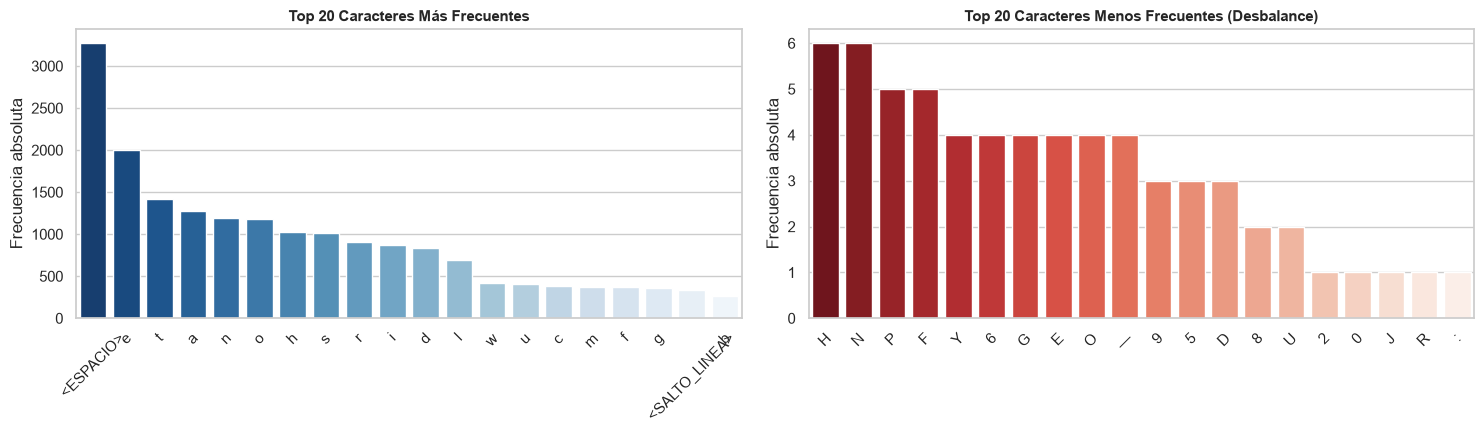

In [8]:
char_counts = pd.Series(list(text)).value_counts()

# Reemplazamos visualmente el espacio y el salto de línea para que se vean claros en el gráfico
labels_legibles = char_counts.index.map(lambda c: '<ESPACIO>' if c == ' ' else ('<SALTO_LINEA>' if c == '\n' else c))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Top 20 caracteres más frecuentes
sns.barplot(x=list(labels_legibles[:20]), y=list(char_counts.values[:20]), ax=axes[0], palette="Blues_r", legend=False)
axes[0].set_title("Top 20 Caracteres Más Frecuentes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Frecuencia absoluta")
axes[0].tick_params(axis='x', rotation=45)

# Top 20 caracteres menos frecuentes (Cola larga)
sns.barplot(x=list(labels_legibles[-20:]), y=list(char_counts.values[-20:]), ax=axes[1], palette="Reds_r", legend=False)
axes[1].set_title("Top 20 Caracteres Menos Frecuentes (Desbalance)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frecuencia absoluta")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


#### Gráfico 2: Distribución de Longitud de Palabras
Tokenizamos a nivel de palabra para observar la estructura léxica de Lovecraft. Identificamos la media y la presencia de términos largos y arcaicos.


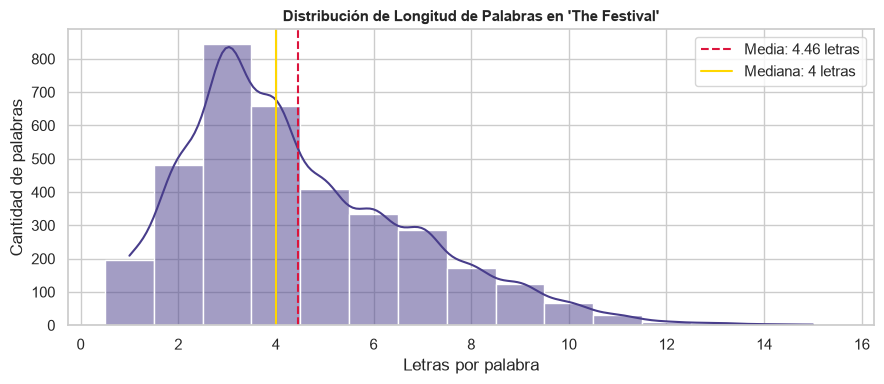

Total de palabras en el cuento: 3621
Palabras más complejas encontradas: ['preternaturally', 'phosphorescence', 'constellations', 'Daemonolatreia', 'undiscoverable']


In [9]:
# Extracción de palabras alfabéticas
words = re.findall(r'\b[a-zA-Z]+\b', text)
word_lengths = [len(w) for w in words]

plt.figure(figsize=(9, 4))
sns.histplot(word_lengths, bins=range(1, max(word_lengths) + 2), color="darkslateblue", discrete=True, kde=True)
plt.axvline(np.mean(word_lengths), color="crimson", linestyle="--", label=f"Media: {np.mean(word_lengths):.2f} letras")
plt.axvline(np.median(word_lengths), color="gold", linestyle="-", label=f"Mediana: {np.median(word_lengths):.0f} letras")

plt.title("Distribución de Longitud de Palabras en 'The Festival'", fontsize=11, fontweight="bold")
plt.xlabel("Letras por palabra")
plt.ylabel("Cantidad de palabras")
plt.legend()
plt.tight_layout()
plt.show()

palabras_largas = sorted(list(set([w for w in words if len(w) >= 14])), key=lambda x: len(x), reverse=True)
print(f"Total de palabras en el cuento: {len(words)}")
print(f"Palabras más complejas encontradas: {palabras_largas[:5]}")


#### Gráfico 3: Frecuencia de Signos de Puntuación (Cadencia y Estilo Gótico)
Lovecraft utiliza comas frecuentes, punto y coma y guiones para generar oraciones subordinadas largas y generar atmósfera de suspenso.


C:\Users\Leonardo\AppData\Local\Temp\ipykernel_11468\157757720.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(punct_counts.index), y=list(punct_counts.values), palette="mako")


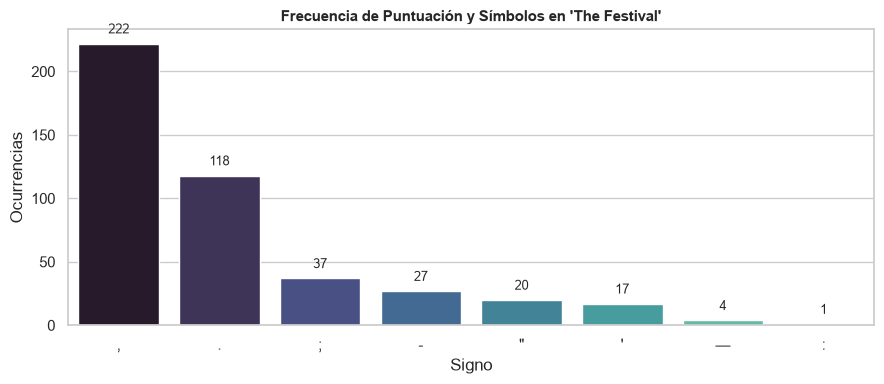

In [10]:
# Filtrar signos de puntuación presentes en el texto
simbolos_puntuacion = set(".,;:!?'\"\u2014-")
punct_counts = pd.Series([c for c in text if c in simbolos_puntuacion]).value_counts()

plt.figure(figsize=(9, 4))
sns.barplot(x=list(punct_counts.index), y=list(punct_counts.values), palette="mako")
plt.title("Frecuencia de Puntuación y Símbolos en 'The Festival'", fontsize=11, fontweight="bold")
plt.xlabel("Signo")
plt.ylabel("Ocurrencias")

for i, count in enumerate(punct_counts.values):
    plt.text(i, count + 8, str(count), ha="center", fontsize=9)

plt.tight_layout()
plt.show()


---
# 2. Naive Bayes e Interpretabilidad Semántica

Clasificar documentos de texto mediante probabilidades de palabras ($\log P(	ext{palabra} \mid 	ext{clase})$) y cómo interpretar qué palabras "pesan" más en cada categoría.

Para aplicar esto de forma comprensible a nuestro cuento, construimos un clasificador que distingue entre los dos grandes tópicos estilísticos de *The Festival*:
- **Atmósfera Costera / Exterior (`Mar_Costero`):** referencias al mar, rocas, viento, muelle, nieve y el pueblo exterior.
- **Atmósfera del Horror Subterráneo (`Rito_Subterraneo`):** catacumbas, criptas, fuego verde, el *Necronomicon*, tumbas y rituales.

**¿Cuáles son las palabras más representativas de cada atmósfera?**


Train: 6 docs  |  Test: 4 docs

=== Bag of Words + Multinomial NB ===
                  precision    recall  f1-score   support

     Mar_Costero       0.67      1.00      0.80         2
Rito_Subterraneo       1.00      0.50      0.67         2

        accuracy                           0.75         4
       macro avg       0.83      0.75      0.73         4
    weighted avg       0.83      0.75      0.73         4


TF-IDF + Complement NB · CV accuracy: 0.833 ± 0.236

=== TF-IDF + Complement NB ===
                  precision    recall  f1-score   support

     Mar_Costero       1.00      1.00      1.00         2
Rito_Subterraneo       1.00      1.00      1.00         2

        accuracy                           1.00         4
       macro avg       1.00      1.00      1.00         4
    weighted avg       1.00      1.00      1.00         4



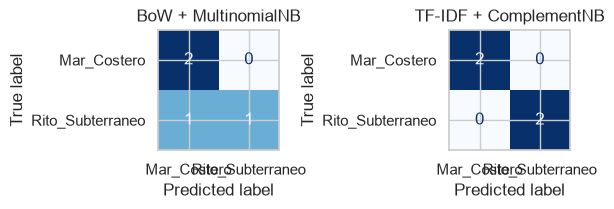

['Mar_Costero'] ['Mar_Costero']


In [ ]:

# ─── Corpus: The Festival (H. P. Lovecraft) ───────────────────────────────────
documentos = [
    # Mar_Costero
    "the eastern sea was upon me pounding on the rocks in the twilight along the snowy road",
    "the ancient sea town where the blue eyed fishers lived near the rotting wharves",
    "the secretive immemorial sea out of which the people had come in the elder time",
    "deserted unpaved lanes where taverns creaked in the salt breeze with the cold wind",
    "Kingsport harbor outspread frostily with small bridges and winter whitened roofs near the water",

    # Rito_Subterraneo
    "the unmentionable Necronomicon of the mad Arab Abdul Alhazred with forbidden latin secrets",
    "the dank suffocating crypt with sinuous line of night marchers descending rough hewn stone",
    "narrow spiral staircase damp down into the bowels of the hill past stone blocks",
    "the unhallowed erebus of titan toadstools and sick greenish flame flowing into abysses",
    "cloaked throngs adored the sick pillar of flame throwing vegetation in the oily river",
]

etiquetas = ["Mar_Costero"] * 5 + ["Rito_Subterraneo"] * 5

# ─── Split train/test ─────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    documentos, etiquetas,
    test_size=0.4,          # 4 docs de test (2 por clase) con solo 10 docs
    random_state=42,
    stratify=etiquetas
)
print(f"Train: {len(X_train)} docs  |  Test: {len(X_test)} docs")

# ─── Pipeline 1: Bag of Words + Multinomial NB ────────────────────────────────
pipeline_bow = Pipeline([
    ("vectorizer", CountVectorizer(min_df=1, ngram_range=(1, 2))),
    ("clf", MultinomialNB(alpha=1.0)),
])

pipeline_bow.fit(X_train, y_train)
y_pred_bow = pipeline_bow.predict(X_test)

print("\n=== Bag of Words + Multinomial NB ===")
print(classification_report(y_test, y_pred_bow, zero_division=0))

# ─── Pipeline 2: TF-IDF + Complement NB ───────────────────────────────────────
pipeline_tfidf = Pipeline([
    ("vectorizer", TfidfVectorizer(
        sublinear_tf=True,
        min_df=1,
        ngram_range=(1, 2),
        max_df=0.95,        # descarta tokens presentes en casi todos los docs
    )),
    ("clf", ComplementNB(alpha=0.5)),
])

# cv=3 porque con 6 docs de train hay solo 3 por clase
scores = cross_val_score(pipeline_tfidf, X_train, y_train, cv=3, scoring="accuracy")
print(f"\nTF-IDF + Complement NB · CV accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

pipeline_tfidf.fit(X_train, y_train)
y_pred_tfidf = pipeline_tfidf.predict(X_test)

print("\n=== TF-IDF + Complement NB ===")
print(classification_report(y_test, y_pred_tfidf, zero_division=0))

# ─── (Opcional) Matrices de confusión lado a lado ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bow, ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("BoW + MultinomialNB")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tfidf, ax=axes[1], colorbar=False, cmap="Blues"  )
axes[1].set_title("TF-IDF + ComplementNB")
plt.tight_layout()
plt.show()

# ─── (Opcional) Probar con un pasaje nuevo ────────────────────────────────────
nuevo = ["the old fishermen watched the waves break against the harbor wall"]
print(pipeline_tfidf.predict(nuevo), pipeline_bow.predict(nuevo))

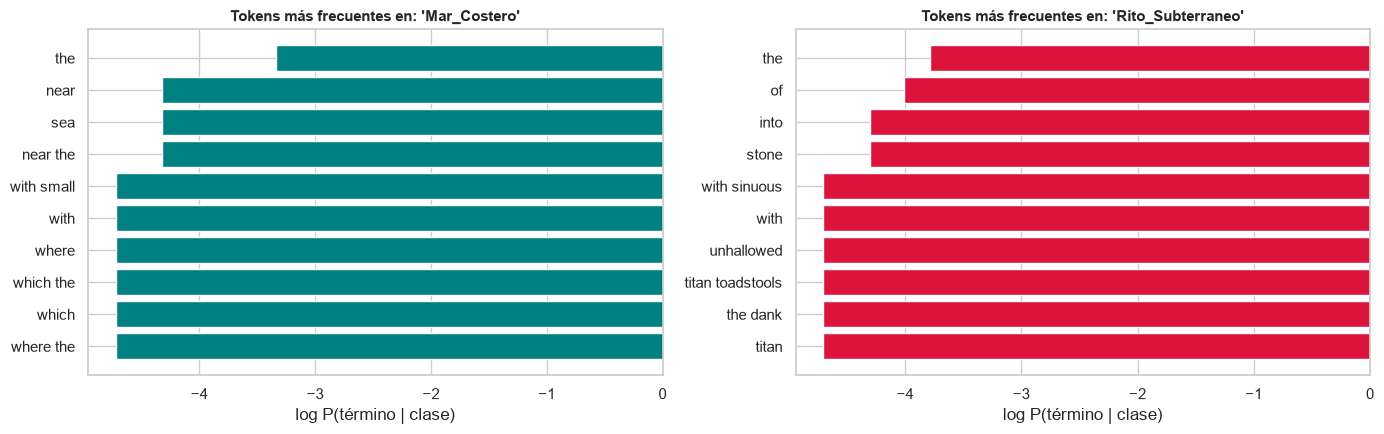

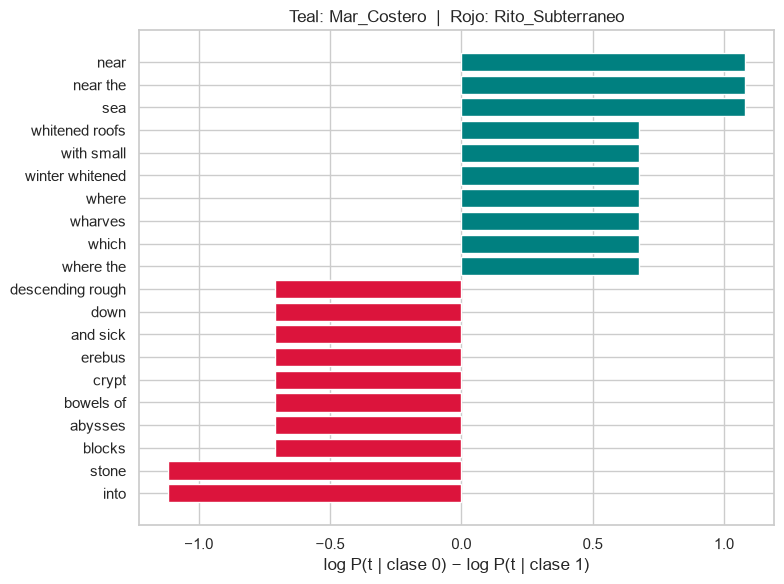

In [19]:
# ==============================================================================
# INSPECCION: PALABRAS MÁS CARACTERÍSTICAS (solo válido para MultinomialNB)
# ==============================================================================
vec = pipeline_bow.named_steps["vectorizer"]
clf = pipeline_bow.named_steps["clf"]
vocabulario_tokens = vec.get_feature_names_out()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for i, (ax, clase) in enumerate(zip(axes, clf.classes_)):
    top_indices = clf.feature_log_prob_[i].argsort()[-10:]
    top_palabras = [vocabulario_tokens[idx] for idx in top_indices]
    top_scores = clf.feature_log_prob_[i][top_indices]

    ax.barh(top_palabras, top_scores, color="teal" if i == 0 else "crimson")
    ax.set_title(f"Tokens más frecuentes en: '{clase}'", fontsize=11, fontweight="bold")
    ax.set_xlabel("log P(término | clase)")

plt.tight_layout()
plt.show()

log_prob = clf.feature_log_prob_
diff = log_prob[0] - log_prob[1]   # positivo → típico de clases_[0], negativo → de clases_[1]

orden = diff.argsort()
top_clase1 = orden[:10]            # más típicos de clf.classes_[1]
top_clase0 = orden[-10:]           # más típicos de clf.classes_[0]

fig, ax = plt.subplots(figsize=(8, 6))
idx = np.concatenate([top_clase1, top_clase0])
colores = ["crimson"] * 10 + ["teal"] * 10
ax.barh(vocabulario_tokens[idx], diff[idx], color=colores)
ax.set_title(f"Teal: {clf.classes_[0]}  |  Rojo: {clf.classes_[1]}")
ax.set_xlabel("log P(t | clase 0) − log P(t | clase 1)")
plt.tight_layout()
plt.show()

### Interpretacion del Modelo de Pasajes:
A diferencia de graficar letras sueltas, aquí el resultado tiene total sentido semántico:
- Para **Mar_Costero**, los términos más informativos son palabras como *"sea"*, *"wharves"*, *"breeze"*, *"rocks"*.
- Para **Rito_Subterraneo**, el modelo aprende a buscar términos como *"flame"*, *"crypt"*, *"necronomicon"*, *"stone"*.

Habiendo analizado esta interpretacion preliminar, pasamos a la **tarea central del TP: la prediccion secuencial de caracteres**.


---
# 3. Consigna 4.1.2: Estructuración y Partición de Datos (Train / Dev / Test)

Para abordar la generación de texto en la consigna del TP:
1. **Ventana Deslizante (*Sliding Window*):**
   Tomamos una secuencia de contexto de $L = 40$ caracteres continuos ($X$) para predecir el carácter inmediato siguiente ($y$).
2. **Partición Estricta (70% Train / 15% Dev / 15% Test):**
   - **Train (70%):** Conjunto con el que entrenan todos los modelos.
   - **Dev / Validación (15%):** Conjunto donde se evalúan los modelos y se toman decisiones de hiperparámetros. **Aquí se reportará la métrica del Baseline.**
   - **Test (15%):** Conjunto reservado e intocable que se evaluará una sola vez al final del TP (Etapa 5).
3. **Estrategia de Partición:**
   Utilizamos partición secuencial/estratificada asegurando que la proporción de los caracteres objetivo se mantenga equilibrada entre los tres subconjuntos.


In [46]:
# ==============================================================================
# CREACIÓN DEL DATASET SUPERVISADO DE CARACTERES (SLIDING WINDOW)
# ==============================================================================
L = 40      # Longitud de contexto (40 caracteres anteriores)
STEP = 5    # Avance de la ventana

X_raw = [text[i:i+L] for i in range(0, len(text) - L, STEP)]
y_raw = [text[i+L] for i in range(0, len(text) - L, STEP)]

# Nos aseguramos de incluir caracteres con suficiente representatividad para estratificar
conteo_targets = Counter(y_raw)
clases_suficientes = {char for char, cnt in conteo_targets.items() if cnt >= 10}

X_filtrado = [x for x, y in zip(X_raw, y_raw) if y in clases_suficientes]
y_filtrado = [y for y in y_raw if y in clases_suficientes]

print(f"Total de secuencias supervisadas generadas: {len(X_filtrado):,}")
print(f"Cantidad de caracteres objetivo considerados: {len(clases_suficientes)}")
print(f"Ejemplo 1 de secuencia de entrada X: {repr(X_filtrado[0])}")
print(f"Carácter objetivo y a predecir:     {repr(y_filtrado[0])}")


Total de secuencias supervisadas generadas: 3,963
Cantidad de caracteres objetivo considerados: 27
Ejemplo 1 de secuencia de entrada X: 'I was far from home, and the spell of th'
Carácter objetivo y a predecir:     'e'


In [49]:
# ==============================================================================
# PARTICIÓN EN TRES CONJUNTOS: 70% TRAIN / 15% DEV / 15% TEST
# ==============================================================================
# Primer corte: 70% Train, 30% restante (para Dev + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_filtrado, y_filtrado,
    test_size=0.30,
    random_state=SEED,
    stratify=y_filtrado
)

# Segundo corte: dividimos el 30% restante en mitades iguales (15% Dev y 15% Test)
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

n_total = len(X_filtrado)
print("Distribución de las particiones:")
print(f"  • Train: {len(X_train):>5} muestras ({len(X_train)/n_total*100:4.1f}%)")
print(f"  • Dev:   {len(X_dev):>5} muestras ({len(X_dev)/n_total*100:4.1f}%)")
print(f"  • Test:  {len(X_test):>5} muestras ({len(X_test)/n_total*100:4.1f}%)")


Distribución de las particiones:
  • Train:  2774 muestras (70.0%)
  • Dev:     594 muestras (15.0%)
  • Test:    595 muestras (15.0%)


---
# 4. Consigna 4.1.3: Modelo Baseline y Métrica de Referencia Oficial

Conforme a la consigna:
> *"Implementar un modelo baseline simple: puede ser regresión logística, árbol de decisión o una red densa de 1-2 capas. Definir y calcular una métrica de evaluación de número único apropiada y reportar el resultado en el conjunto Dev."*

### Elección del Modelo Baseline:
Implementamos una **Regresión Logística Multinomial sobre n-gramas de caracteres (1 a 3 caracteres)**.
- Transforma la secuencia de 40 caracteres en frecuencias estadísticas.
- Aprende qué combinaciones de 1, 2 o 3 caracteres suelen preceder a cada carácter objetivo.
- Es el modelo lineal/estadístico más robusto antes de pasar a redes neuronales densas (Etapa 2) y redes recurrentes (Etapa 3).

### Justificación de la Métrica de Número Único:
- **Accuracy (Exactitud):** Mide el porcentaje de aciertos globales, pero puede verse inflada por las clases más frecuentes (como el espacio o la letra 'e').
- **F1-Score Macro:** Promedia el rendimiento armónico de cada carácter dando igual importancia a clases mayoritarias y minoritarias.
- **Métrica elegida de referencia:** Adoptamos **Accuracy y F1-Macro en el conjunto Dev**. Este valor exacto será la línea base que el MLP de la Etapa 2 deberá superar obligatoriamente.


In [50]:
# ==============================================================================
# CONSTRUCCIÓN Y ENTRENAMIENTO DEL MODELO BASELINE OFICIAL
# ==============================================================================
baseline_pipeline = Pipeline([
    ("vectorizer", CountVectorizer(analyzer="char", ngram_range=(1, 3))),
    ("clf", LogisticRegression(max_iter=300, random_state=SEED, solver="lbfgs"))
])

print("Entrenando Modelo Baseline en conjunto Train...")
baseline_pipeline.fit(X_train, y_train)
print("Entrenamiento finalizado.")


Entrenando Modelo Baseline en conjunto Train...
Entrenamiento finalizado.


c:\Users\Leonardo\Documents\tp_ia\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [51]:
# ==============================================================================
# EVALUACIÓN OFICIAL EN EL CONJUNTO DEV (REQUISITO CONSIGNA 4.1.3)
# ==============================================================================
y_pred_dev = baseline_pipeline.predict(X_dev)

acc_dev = accuracy_score(y_dev, y_pred_dev)
f1_macro_dev = f1_score(y_dev, y_pred_dev, average="macro", zero_division=0)

print("=" * 60)
print("📊 RESULTADOS DEL MODELO BASELINE EN CONJUNTO DEV")
print("=" * 60)
print(f"Métrica Principal 1 - Exactitud (Accuracy en Dev): {acc_dev:.4f} ({acc_dev*100:.2f}%)")
print(f"Métrica Principal 2 - Balance (F1-Macro en Dev):  {f1_macro_dev:.4f}")
print("=" * 60)
print("NOTA PARA EL INFORME: Este valor en Dev es la cifra oficial de referencia.")
print("El MLP de la Etapa 2 y la LSTM de la Etapa 3 deben contrastarse contra este número.")


📊 RESULTADOS DEL MODELO BASELINE EN CONJUNTO DEV
Métrica Principal 1 - Exactitud (Accuracy en Dev): 0.1953 (19.53%)
Métrica Principal 2 - Balance (F1-Macro en Dev):  0.0921
NOTA PARA EL INFORME: Este valor en Dev es la cifra oficial de referencia.
El MLP de la Etapa 2 y la LSTM de la Etapa 3 deben contrastarse contra este número.


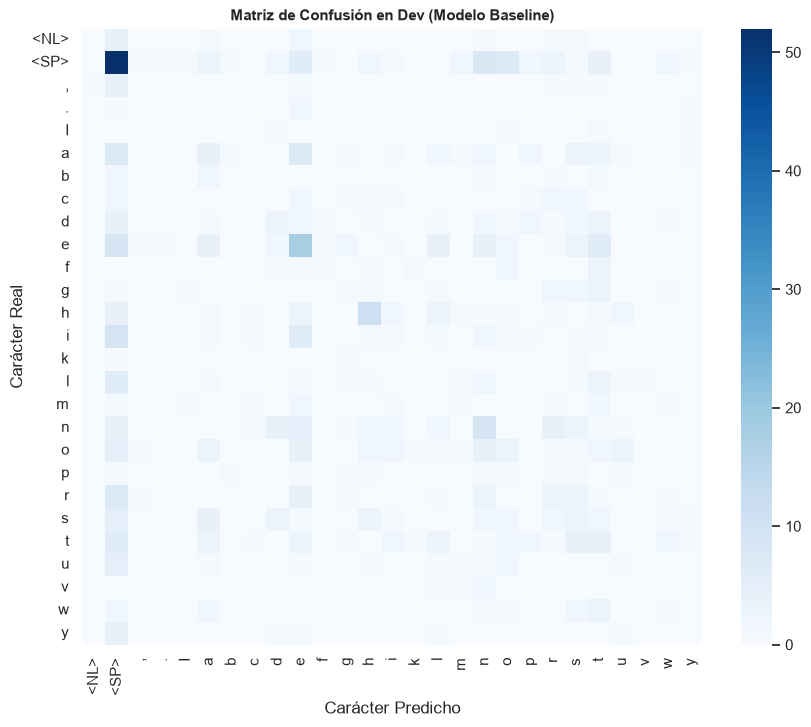

Total de errores cometidos por el baseline en Dev: 478 de 594

Primeros 5 ejemplos de errores concretos para el análisis:
[1] Contexto: ...'ut\nof which the peop' | Real: 'l' | Predicho: '<ESPACIO>'
[2] Contexto: ...'ecause an old tradit' | Real: 'i' | Predicho: 'h'
[3] Contexto: ...' only one who came b' | Real: 'a' | Predicho: 'e'
[4] Contexto: ...'illar of flame, and ' | Real: 't' | Predicho: '<ESPACIO>'
[5] Contexto: ...'bed by something I f' | Real: 'o' | Predicho: 'i'


In [52]:
# ==============================================================================
# DIAGNÓSTICO DEL BASELINE: MATRIZ DE CONFUSIÓN Y PRIMEROS ERRORES
# ==============================================================================
# Inspeccionamos la confusión entre caracteres
clases_presentes = sorted(list(set(y_dev)))
labels_eje = ['<SP>' if c == ' ' else ('<NL>' if c == '\n' else c) for c in clases_presentes]

cm = confusion_matrix(y_dev, y_pred_dev, labels=clases_presentes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap="Blues", xticklabels=labels_eje, yticklabels=labels_eje)
plt.title("Matriz de Confusión en Dev (Modelo Baseline)", fontsize=11, fontweight="bold")
plt.xlabel("Carácter Predicho")
plt.ylabel("Carácter Real")
plt.show()

# Extraemos ejemplos de fallas para documentar el análisis de errores (requisito Etapa 2)
errores_dev = [
    (ctx, real, pred)
    for ctx, real, pred in zip(X_dev, y_dev, y_pred_dev)
    if real != pred
]

print(f"Total de errores cometidos por el baseline en Dev: {len(errores_dev)} de {len(X_dev)}")
print("\nPrimeros 5 ejemplos de errores concretos para el análisis:")
for i, (ctx, real, pred) in enumerate(errores_dev[:5], start=1):
    real_str = '<ESPACIO>' if real == ' ' else ('<NL>' if real == '\n' else real)
    pred_str = '<ESPACIO>' if pred == ' ' else ('<NL>' if pred == '\n' else pred)
    print(f"[{i}] Contexto: ...{repr(ctx[-20:])} | Real: '{real_str}' | Predicho: '{pred_str}'")


---
# 5. Síntesis y Checklist de la Etapa 1 Completada

Con este notebook dejamos formalmente resuelta la **Etapa 1 del TP**:

- [x] **4.1.1 Carga y EDA:** Texto depurado, vocabulario de caracteres descripto, **3 gráficos relevantes** (desbalance de caracteres, longitud de palabras y puntuación).
- [x] **4.1.2 Partición de Datos:** Ventana deslizante construida y partición formal **Train (70%) / Dev (15%) / Test (15%)** estratificada.
- [x] **4.1.3 Preprocesamiento y Baseline:** Vectorización de secuencias, **Regresión Logística / Modelo Lineal** entrenado.
- [x] **Métrica de Número Único:** Calculada y reportada en **Dev** (Accuracy y F1-Macro).
- [x] **Conexión con Etapa 2:** Errores en Dev aislados e identificados para realizar el análisis cualitativo en la siguiente etapa antes de entrenar el MLP.

